In [1]:
from scipy.io import readsav
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# out = readsav('/Users/jmdunca2/Desktop/MEGADEMS PAPERs/P1 TEX/Review 1/out.sav')

# fig,ax = plt.subplots()
# lf = ax.plot(out['eb'][0:-1],out['xrth'][0],color = 'black',label = 'f_vth')[0]
# lc = ax.plot(out['spc']['lambda'][0],out['spc']['spectrum'][0],color = 'red',label = 'CHIANTI v'+out['spc']['version'][0].decode())[0]
# ax.set(xlabel = 'Energy (keV)',ylabel = r'Flux at Earth (ph cm$^{-2}$ s$^{-1}$ keV$^{-1}$',yscale = 'log', ylim = [1e0, 1e8])
# lb = ax.text(8,5e7,f'T = {10**out["logt"][0]/1e6:0.1f} MK')
# ax.legend()
# ax.set_xlim([2.,10.])

# def ani(i):
#   lf.set_ydata(out['xrth'][i])
#   lc.set_ydata(out['spc']['spectrum'][i])
#   lb.set_text(f'T = {10**out["logt"][i]/1e6:0.1f} MK')
#   return [lf,lc,lb]


# a = animation.FuncAnimation(fig, ani, frames = 41)
# writer = animation.FFMpegWriter(fps=10)
# a.save('sxr_edit.mp4',writer=writer)


In [55]:
print(out['spc']['lambda'][0][0])
print(out['e'][0])
print(out['eb'][0])

2.01
2.01
2.005


In [25]:
#Temperatures:
print(out["logt"])

#CHIANTI V11 Joel Spectra (first temp):
#print(out['spc']['spectrum'][0])

#F_VTH spectra (CHIANTI V9):
#print(out['xrth'][0])

[6.   6.05 6.1  6.15 6.2  6.25 6.3  6.35 6.4  6.45 6.5  6.55 6.6  6.65
 6.7  6.75 6.8  6.85 6.9  6.95 7.   7.05 7.1  7.15 7.2  7.25 7.3  7.35
 7.4  7.45 7.5  7.55 7.6  7.65 7.7  7.75 7.8  7.85 7.9  7.95 8.  ]


In [30]:
out['e']

array([ 1.64      ,  1.68      ,  1.72      ,  1.76      ,  1.8       ,
        1.83999999,  1.87999999,  1.91999999,  1.95999999,  1.99999999,
        2.03999999,  2.07999999,  2.11999999,  2.15999999,  2.19999999,
        2.23999999,  2.27999998,  2.31999998,  2.35999998,  2.39999998,
        2.43999998,  2.47999998,  2.51999998,  2.55999998,  2.59999998,
        2.63999998,  2.67999998,  2.71999997,  2.75999997,  2.79999997,
        2.83999997,  2.87999997,  2.91999997,  2.95999997,  2.99999997,
        3.03999997,  3.07999997,  3.11999997,  3.15999997,  3.19999996,
        3.23999996,  3.27999996,  3.31999996,  3.35999996,  3.39999996,
        3.43999996,  3.47999996,  3.51999996,  3.55999996,  3.59999996,
        3.63999995,  3.67999995,  3.71999995,  3.75999995,  3.79999995,
        3.83999995,  3.87999995,  3.91999995,  3.95999995,  3.99999995,
        4.03999995,  4.07999994,  4.11999994,  4.15999994,  4.19999994,
        4.23999994,  4.27999994,  4.31999994,  4.35999994,  4.39

In [26]:
out.keys()

dict_keys(['output', 'spc', 'sp', 'e', 'logt', 'logem'])

In [17]:
np.shape(out['xrth'])

(41, 800)

In [27]:
np.shape(np.stack(out['spc']['spectrum']).T)

(960, 41)

In [ ]:
xrth[*,i] = f_vth(eb,[1.0,!kb*1d-3*10d0^logt[i],1.])
fvth[i,*]=f_vth(engs,[1,tkev[i],1])

In [2]:
path_to_dodem = '/Users/jmdunca2/do-dem/'
from sys import path as sys_path
sys_path.append(path_to_dodem+'/dodem/')

import nustar_dem_prep as nu

import pickle
import importlib

importlib.reload(nu)

key='11-dec-22_2'

with open('/Users/jmdunca2/do-dem/reference_files/all_targets_postghost_postshut.pickle', 'rb') as f:
    all_targets = pickle.load(f)

file = all_targets[key]['res_file_dict(s)'][0]['quiet files all-inst'][0]
with open(file, 'rb') as f:
    data = pickle.load(f)
time = data['time_interval']

print(file)

ARDict = all_targets[key]
nustar_path = ARDict['working_dir']+'region_0/'
id_dirs = ARDict['datapaths']
obsids = ARDict['obsids']

make_nustar=True

eng_tr=[[2.,4.],[4.,6.],[6.,10.]]
fpm='A'

o=0

datapath=id_dirs[o]
gtifile=datapath+'event_cl/nu'+obsids[o]+'A06_gti.fits'
regfile=path_to_dodem+'starter_region.reg'



# res1 = nu.load_nustar(time, eng_tr, nustar_path, fpm, make_nustar=False, gtifile=gtifile, datapath=datapath, regfile=regfile, 
#                    actual_total_counts=False, centroid_region=False,
#                    clobber=False, default_err=0.2, pile_up_corr=True,
#                    adjacent_grades=True,
#                      path_to_dodem=path_to_dodem, shush=False, check_chianti_v=True)

# res2 = nu.load_nustar(time, eng_tr, nustar_path, fpm, make_nustar=False, gtifile=gtifile, datapath=datapath, regfile=regfile, 
#                    actual_total_counts=False, centroid_region=False,
#                    clobber=False, default_err=0.2, pile_up_corr=True,
#                    adjacent_grades=True,
#                      path_to_dodem=path_to_dodem, shush=False, check_chianti_v=False)

/Users/jmdunca2/do-dem/DEM_folders//initial_dem_11dec22_2/region_0//22-18-10_22-19-55/22-18-10_22-19-55_5.6_7.2_11-dec-22_2_MC_DEM_result_withparams.pickle


In [72]:
res1[4][1:]

array([6.05, 6.1 , 6.15, 6.2 , 6.25, 6.3 , 6.35, 6.4 , 6.45, 6.5 , 6.55,
       6.6 , 6.65, 6.7 , 6.75, 6.8 , 6.85, 6.9 , 6.95, 7.  , 7.05, 7.1 ,
       7.15, 7.2 , 7.25, 7.3 , 7.35, 7.4 , 7.45, 7.5 , 7.55, 7.6 , 7.65,
       7.7 , 7.75, 7.8 , 7.85, 7.9 , 7.95, 8.  ], dtype='>f4')

In [65]:
res2[4]

array([6.05     , 6.1000004, 6.15     , 6.2000003, 6.25     , 6.3      ,
       6.3500004, 6.4      , 6.4500003, 6.5      , 6.55     , 6.6000004,
       6.65     , 6.7000003, 6.75     , 6.8      , 6.8500004, 6.9      ,
       6.9500003, 7.       , 7.05     , 7.1000004, 7.15     , 7.2000003,
       7.25     , 7.3      , 7.3500004, 7.4      , 7.4500003, 7.5      ,
       7.55     , 7.6000004, 7.65     , 7.7000003, 7.75     , 7.8      ,
       7.8500004, 7.9      , 7.9500003, 8.       ], dtype='>f4')

/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2356939854.py:12: RuntimeWarning: divide by zero encountered in divide
  plt.plot(res1[4][1:], res1[3][:,0][1:]/res2[3][:,0], label=res1[2][0]+' Ratio, res1/res2')
/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2356939854.py:13: RuntimeWarning: divide by zero encountered in divide
  plt.plot(res2[4], res1[3][:,1][1:]/res2[3][:,1], label=res1[2][1]+' Ratio, res1/res2')
/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2356939854.py:14: RuntimeWarning: divide by zero encountered in divide
  plt.plot(res1[4][1:], res1[3][:,2][1:]/res2[3][:,2], label=res1[2][2]+' Ratio, res1/res2')
/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2356939854.py:22: RuntimeWarning: divide by zero encountered in divide
  plt.plot(res2[4], res2[0][0]/res2[3][:,0], label=res2[2][0]+' 2')
/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2356939854.py:23: RuntimeWarning: divide by zero

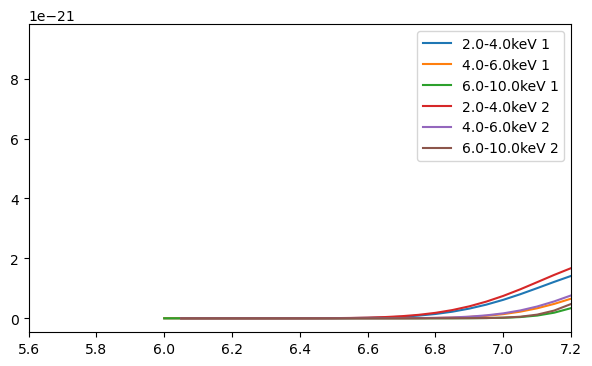

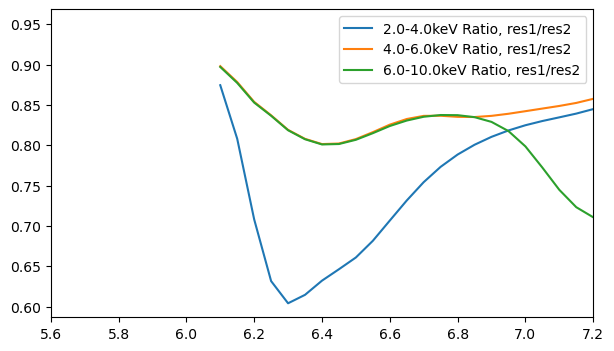

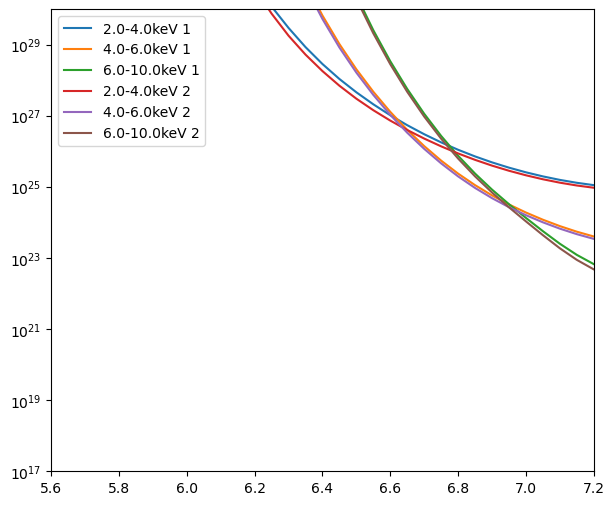

In [73]:
# plt.figure(figsize=(7,4))
# plt.plot(res1[4], res1[3][:,0], label=res1[2][0]+' 1')
# plt.plot(res1[4], res1[3][:,1], label=res1[2][1]+' 1')
# plt.plot(res1[4], res1[3][:,2], label=res1[2][2]+' 1')
# plt.plot(res2[4], res2[3][:,0], label=res2[2][0]+' 2')
# plt.plot(res2[4], res2[3][:,1], label=res2[2][1]+' 2')
# plt.plot(res2[4], res2[3][:,2], label=res2[2][2]+' 2')
# plt.xlim([5.6,7.2])
# plt.legend()

# plt.figure(figsize=(7,4))
# plt.plot(res1[4][1:], res1[3][:,0][1:]/res2[3][:,0], label=res1[2][0]+' Ratio, res1/res2')
# plt.plot(res2[4], res1[3][:,1][1:]/res2[3][:,1], label=res1[2][1]+' Ratio, res1/res2')
# plt.plot(res1[4][1:], res1[3][:,2][1:]/res2[3][:,2], label=res1[2][2]+' Ratio, res1/res2')
# plt.xlim([5.6,7.2])
# plt.legend()

# plt.figure(figsize=(7,6))
# plt.plot(res1[4], res1[0][0]/res1[3][:,0], label=res1[2][0]+' 1')
# plt.plot(res1[4], res1[0][1]/res1[3][:,1], label=res1[2][1]+' 1')
# plt.plot(res1[4], res1[0][2]/res1[3][:,2], label=res1[2][2]+' 1')
# plt.plot(res2[4], res2[0][0]/res2[3][:,0], label=res2[2][0]+' 2', linestyle='dashed')
# plt.plot(res2[4], res2[0][1]/res2[3][:,1], label=res2[2][1]+' 2', linestyle='dashed')
# plt.plot(res2[4], res2[0][2]/res2[3][:,2], label=res2[2][2]+' 2', linestyle='dashed')
# plt.yscale('log')
# plt.xlim([5.6,7.2])
# plt.ylim([1e17,1e30])
# plt.legend()


In [3]:
aia_resp_new = '/Users/jmdunca2/Desktop/MEGADEMS PAPERs/P1 TEX/Review 1/aia_tresp_chiantiv11_google.dat'
aia_tresp=readsav(aia_resp_new)

#For each AIA channel, make a nicer formatted channel name:
for i in np.arange(len(aia_tresp['channels'])):
    aia_tresp['channels'][i]=aia_tresp['channels'][i].decode("utf-8")
chans=np.array(aia_tresp['channels']) 

# Get the temperature response functions in the correct form for dem input
#Define the list of temperatures for which we have AIA response values
tresp_logt=np.array(aia_tresp['logt'])

aia_tr = aia_tresp['tr'] #AIA temperature response function is in units of [DN cm^5 s^-1 pix^-1]


NameError: name 'np' is not defined

In [78]:
np.shape(aia_tr)

(6, 101)

/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2002615474.py:16: RuntimeWarning: divide by zero encountered in divide
  plt.plot(res2[4], res2[0][0]/res2[3][:,0], label=res2[2][0]+' 2', linestyle='dashed')
/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2002615474.py:17: RuntimeWarning: divide by zero encountered in divide
  plt.plot(res2[4], res2[0][1]/res2[3][:,1], label=res2[2][1]+' 2', linestyle='dashed')
/var/folders/55/06y21cm93w70z_8gl7yxv2t40000gq/T/ipykernel_83101/2002615474.py:18: RuntimeWarning: divide by zero encountered in divide
  plt.plot(res2[4], res2[0][2]/res2[3][:,2], label=res2[2][2]+' 2', linestyle='dashed')


(1e+17, 1e+30)

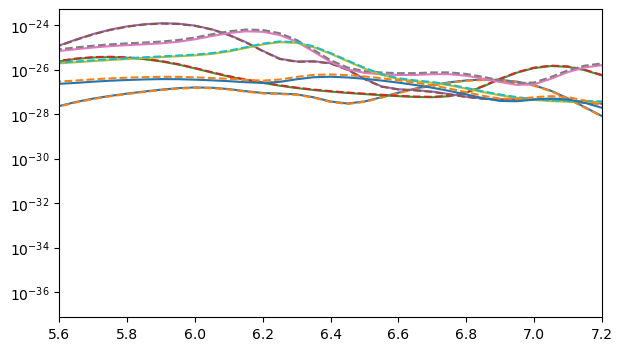

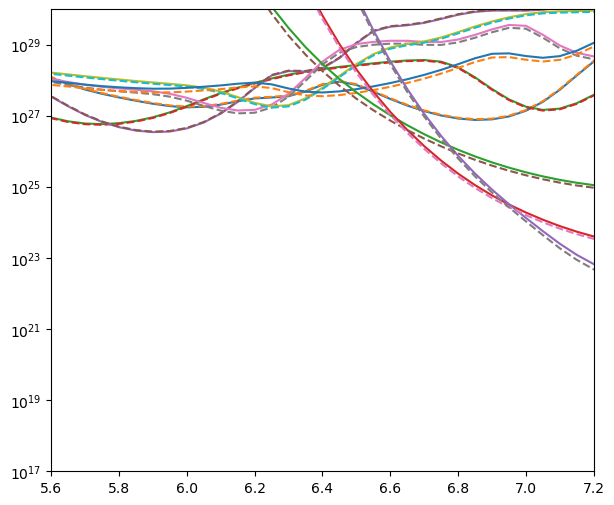

In [98]:
plt.figure(figsize=(7,4))
for i in range(0,6):
    plt.plot(tresp_logt,aia_tr[i,:])
    plt.plot(tresp_logt, data['trmatrix'][:,i], linestyle='dashed')
plt.yscale('log')
plt.xlim([5.6,7.2])

plt.figure(figsize=(7,6))
for i in range(0,6):
    plt.plot(tresp_logt, data['dn_in'][i]/aia_tr[i,:])
    plt.plot(tresp_logt, data['dn_in'][i]/data['trmatrix'][:,i], linestyle='dashed')

plt.plot(res1[4], res1[0][0]/res1[3][:,0], label=res1[2][0]+' 1')
plt.plot(res1[4], res1[0][1]/res1[3][:,1], label=res1[2][1]+' 1')
plt.plot(res1[4], res1[0][2]/res1[3][:,2], label=res1[2][2]+' 1')
plt.plot(res2[4], res2[0][0]/res2[3][:,0], label=res2[2][0]+' 2', linestyle='dashed')
plt.plot(res2[4], res2[0][1]/res2[3][:,1], label=res2[2][1]+' 2', linestyle='dashed')
plt.plot(res2[4], res2[0][2]/res2[3][:,2], label=res2[2][2]+' 2', linestyle='dashed')
plt.yscale('log')
plt.yscale('log')
plt.xlim([5.6,7.2])
plt.ylim([1e17,1e30])

In [4]:

#FOR UPDATING NEWER KEY DICTIONARY TO HAVE THE OLD AIA PATHS
def update_prepped_aia(key, currentfile='', updatefile='', 
                       demfolder='/Users/jmdunca2/do-dem/DEM_folders/'):
    
    with open(updatefile, 'rb') as f:
        data = pickle.load(f)
    
    prepped_aia_toupdate = data[key]['prepped_aia']
    prepped_aia_new = demfolder+('/').join(prepped_aia_toupdate.split('/')[-3:])
                                       
    with open(currentfile, 'rb') as f:
        data = pickle.load(f)
                                           
    data[key]['prepped_aia'] = prepped_aia_new
                                           
    with open(currentfile, 'wb') as f:
        #Pickle the 'data' dictionary using the highest protocol available.
        pickle.dump(data, f, pickle.HIGHEST_PROTOCOL) 


In [13]:
import all_nu_analysis as ana

#keys=['12-apr-19']
keys=['09-sep-18']

importlib.reload(ana)

file='/Users/jmdunca2/do-dem/reference_files/all_targets_postghost_postshut.pickle'


for key in keys:
    print(key)
    #Need to point to the NCCS inputs (if this has not yet been done). Using an old file to update the current megadict.
    update_prepped_aia(key, currentfile=file,
                      updatefile='/Users/jmdunca2/do-dem/reference_files/all_targets.pickle')
    
    with open(file, 'rb') as f:
         data = pickle.load(f)
    
    # ARDict = data[key]
    # #print(ARDict.keys())
    
    
    # prqti2 = ARDict['per_region_quiet_time_intervals']


    
    ana.do_key_dem(key, file, 
                   quiet_only=False,
                   extraname='chanti_v11',
                   mc_rounds=1000,
                   asym_stdv_uncert=True,
                   plot_xrt=False, plot_aia=False,
                   use_prior_prep=False,
                   use_prepped_aia=True,
                   high_temp_analysis=True, rscl=True,
                   do_no_xrt_version=False,
                   do_onlyaia_version=False,
                   do_aiaxrt_version=False)
    

09-sep-18
NAME BEFORE:  09-sep-18chanti_v11
NAME AFTER:  09-sep-18chanti_v11
XRT is:  False
08-50-05 09-02-10
5.6 7.2
Start Time:  2018-09-09 08:50:05
Stop Time:  2018-09-09 09:02:10

Using input regfile:
starter_region.reg
Using grades 0-4 NuSTAR events.
ARF File:  ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_9sep18/08-50-05_09-02-10/nu80414201001A06_0_4_p_sr.arf']
RMF File:  ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_9sep18/08-50-05_09-02-10/nu80414201001A06_0_4_p_sr.rmf']
PHA File:  ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_9sep18/08-50-05_09-02-10/nu80414201001A06_0_4_p_sr.pha']
ARF File:  ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_9sep18/08-50-05_09-02-10/nu80414201001A06_21_24_p_sr.arf']
RMF File:  ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_9sep18/08-50-05_09-02-10/nu80414201001A06_21_24_p_sr.rmf']
PHA File:  ['/Users/jmdunca2/do-dem/DEM_folders//initial_dem_9sep18/08-50-05_09-02-10/nu80414201001A06_21_24_p_sr.pha']

CURRENTLY HARDCODED TO CHIANT

In [11]:
import numpy as np

directory = '/Users/jmdunca2/do-dem/DEM_folders/initial_dem_9sep18/08-50-05_09-02-10/'

file11 = '08-50-05_09-02-10_5.6_7.2_09-sep-18chanti_v11_MC_DEM_result.pickle'
file9 = '08-50-05_09-02-10_5.6_7.2_09-sep-18_MC_DEM_result.pickle'

#directory = '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_12apr19/15-52-25_15-52-55/'
#directory = '/Users/jmdunca2/do-dem/DEM_folders//initial_dem_12apr19/15-12-55_15-16-05/'


#file11 = '15-52-25_15-52-55_5.6_7.2_12-apr-19chanti_v11_MC_DEM_result.pickle'
#file9 = '15-52-25_15-52-55_5.6_7.2_12-apr-19_MC_DEM_result.pickle'


#file11 = '15-12-55_15-16-05_5.6_7.2_12-apr-19chanti_v11_MC_DEM_result.pickle'
#file9 = '15-12-55_15-16-05_5.6_7.2_12-apr-19_MC_DEM_result.pickle'

def compare_files(file1, file2):
    
    with open(file1, 'rb') as f:
        data1 = pickle.load(f)
    with open(file2, 'rb') as f:
        data2 = pickle.load(f)
        

    lower1 = np.array(data1['DEM'])-np.array(data1['edem'][0])
    upper1 = np.array(data1['DEM'])+np.array(data1['edem'][1])

    lower2 = np.array(data2['DEM'])-np.array(data2['edem'][0])
    upper2 = np.array(data2['DEM'])+np.array(data2['edem'][1])

    if np.any(lower1 > upper2):
        print(file1, file2)

    if np.any(lower2 > upper1):
        print(file1, file2)

#for ff in filepairs:
#    compare_files(ff[0], ff[1])

filepair = (directory+file11, directory+file9)

compare_files(*filepair)


_12apr19_v11


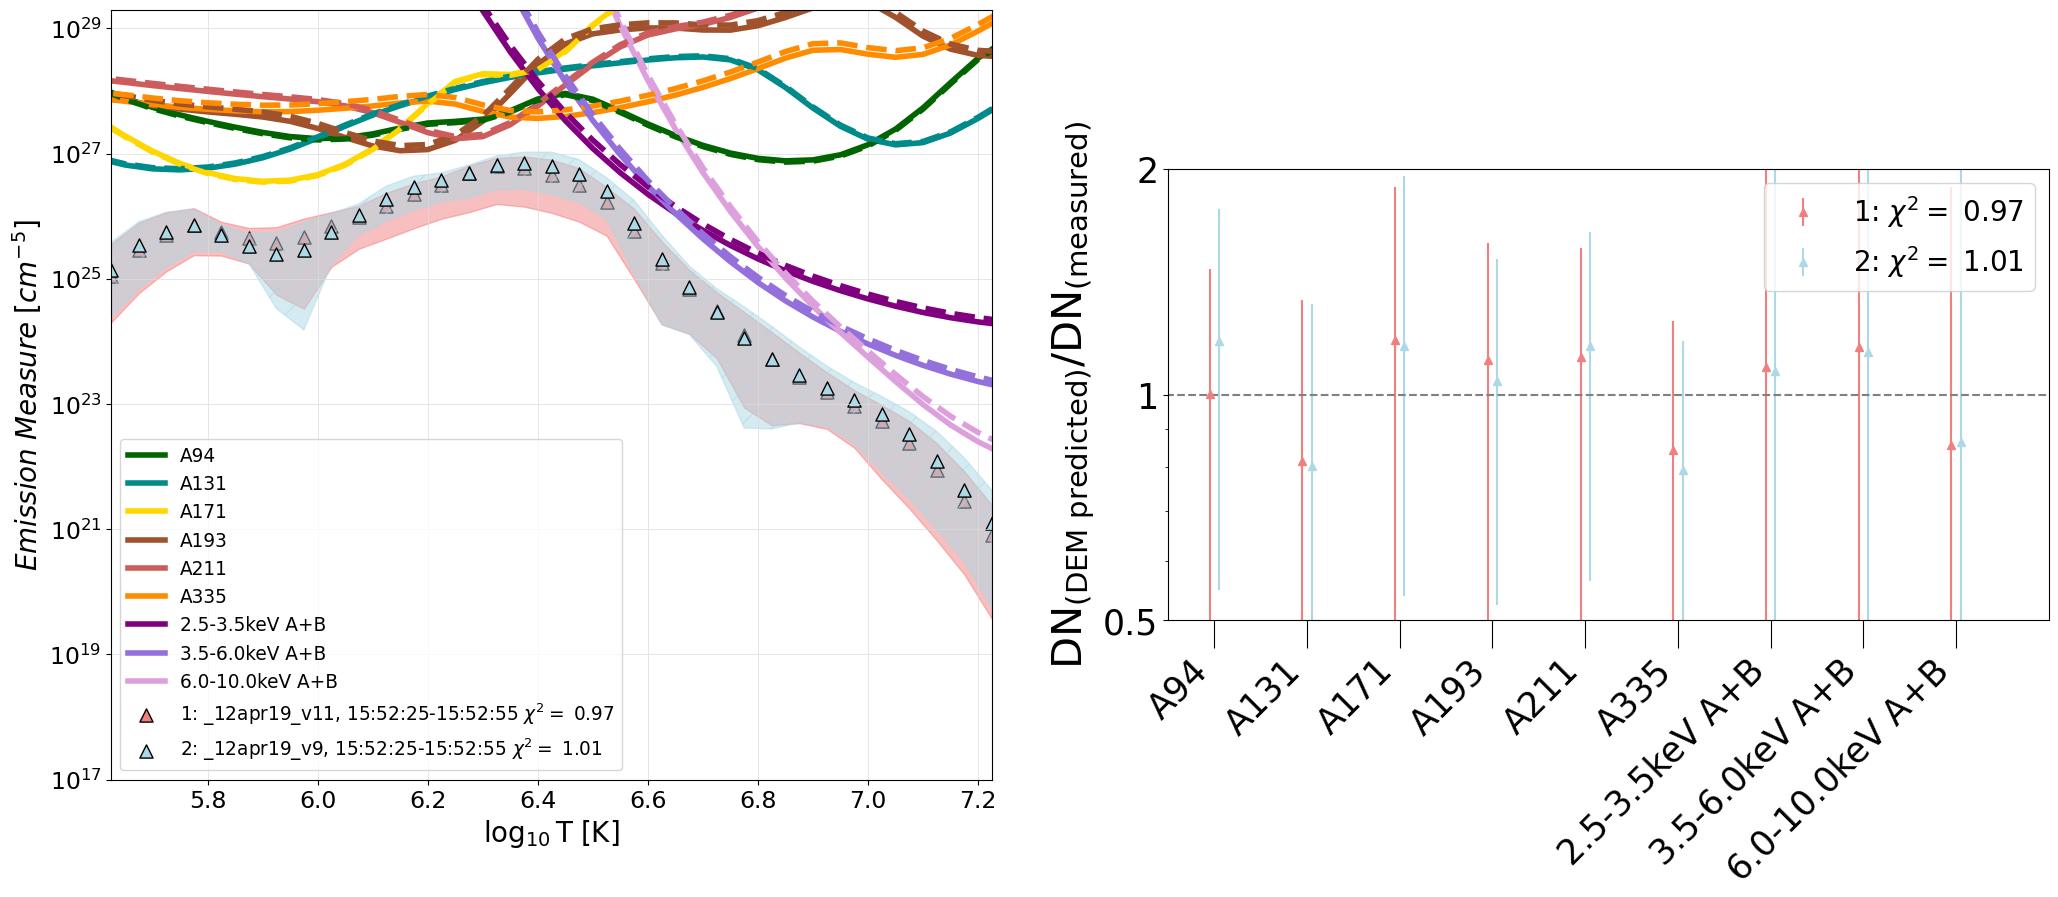

In [12]:
filepairs=[filepair]

import visualize_dem_results as viz

labelfontsize=20

def mod_timestring(timestring):
    modts=(':').join(timestring.split('-'))
    modts=('-').join(modts.split('_'))
    return modts

for pp in filepairs:
    data1, timestring1, time1 = viz.load_DEM(pp[1])
    data2, timestring2, time2 = viz.load_DEM(pp[0])
    namest=pp[1].split('/')[6][11:]+'_v11'
    namest2=pp[0].split('/')[6][11:]+'_v9'
    print(namest)

    fig = plt.figure(constrained_layout=True, figsize=(25,10))
    gs = fig.add_gridspec(5, 2)
    ax1 = fig.add_subplot(gs[0:5, 0])
    ax2 = fig.add_subplot(gs[1:4, 1])

    
    working_dir = '/Users/jmdunca2/do-dem/figures_etc/consistency_plots/'

    importlib.reload(viz)


    viz.compare_DEMs(data1, data2, timestring1, timestring2, title1=namest+', '+mod_timestring(timestring1), 
                     title2=namest2+', '+mod_timestring(timestring2), 
                     plotMK=False, plot=True, working_dir=working_dir, input_ax=ax1, input_ax2=ax2)
    
    ax1.tick_params(axis='both', labelsize=17)
    #ax1.set_title('Comparison - Two Quiescent Times on '+namest, fontsize=labelfontsize)
    ax1.set_title('', fontsize=labelfontsize)

    #ax2.set_title('Residuals', fontsize=labelfontsize)
    ax2.set_title('', fontsize=labelfontsize)
    ax1.set_ylim([1e17, 2e29])
    ax1.legend(ncols=1, fontsize=labelfontsize/1.5)

    plt.savefig('09-sep-18_chianti_comparison.png', dpi=300)
    #plt.savefig('12-apr-19_chianti_comparison.png', dpi=300)


Everything below here is from an attempt to use ChiantiPy to make x-ray spectra at various temperatures, which was confusing and unsuccessful.

Due to needing a newer numpy than I already had, this must be run in the update_np_env environment.

In [1]:
import os

os.environ['XUVTOP']

import ChiantiPy
import ChiantiPy.core as ch
import ChiantiPy.tools.filters as chfilters
import ChiantiPy.tools.io as chio
import numpy as np
import matplotlib.pyplot as plt

 ChiantiPy version 0.16.0 
 found PyQt5 widgets
 using PyQt5 widgets


In [2]:
matplotlib inline

In [35]:
temperature = [5.e+6]
density = 1.e+10
wvl = 200. + 0.05*np.arange(2001)
emeasure = np.array([1.e+27])

In [27]:
from astropy import units as u
de=0.04
#energies_of_interest = np.arange(1.6, 40, 0.04)*u.keV
energies_of_interest = np.arange(2., 40, 0.04)*u.keV
wvn_interest = energies_of_interest.to(u.Angstrom, equivalencies=u.spectral()).value

In [28]:
#checking the values seem reasonable
print(energies_of_interest[0:20])
print(wvn_interest[0:20])

[1.6  1.64 1.68 1.72 1.76 1.8  1.84 1.88 1.92 1.96 2.   2.04 2.08 2.12
 2.16 2.2  2.24 2.28 2.32 2.36] keV
[7.7490124  7.5600121  7.38001181 7.20838363 7.04455673 6.88801102
 6.73827165 6.59490417 6.45751034 6.32572441 6.19920992 6.07765679
 5.96077877 5.84831125 5.74000919 5.63564538 5.53500886 5.43790344
 5.34414648 5.25356773]


In [88]:
#filter = (chfilters.gaussian,.2),
s = ch.spectrum(temperature, density, wvn_interest, filter = (chfilters.gaussianR,1000),
                em = emeasure, doContinuum=1, doLines=1, elementList=['fe','ni', 'ca', 'cr'], #minAbund=1.e-7,
               abundance='sun_coronal_2021_chianti')


line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb
line_ff_fb


TypeError: iteration over a 0-d array

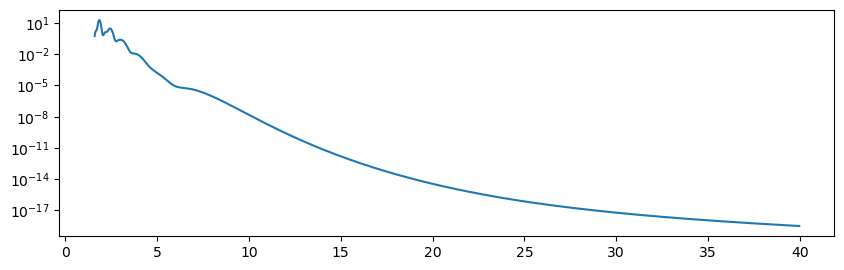

In [25]:
plt.figure(figsize=(10,10))

plt.subplot(311)
plt.plot(energies_of_interest, s.Spectrum['integrated'])
#plt.subplot(312)
#plt.plot(wvn_interest, s.Spectrum['intensity'])
#plt.subplot(313)
#plt.plot(wvn_interest, s.Spectrum['intensity'][1])
plt.yscale('log')

(2.0, 15.0)

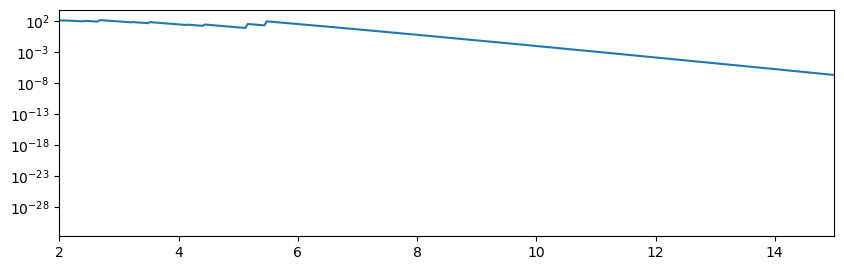

In [73]:
plt.figure(figsize=(10,10))

plt.subplot(311)
plt.plot(energies_of_interest, s.Spectrum['integrated'])
#plt.subplot(312)
#plt.plot(wvn_interest, s.Spectrum['intensity'])
#plt.subplot(313)
#plt.plot(wvn_interest, s.Spectrum['intensity'][1])
plt.yscale('log')
plt.xlim([2.,15.])

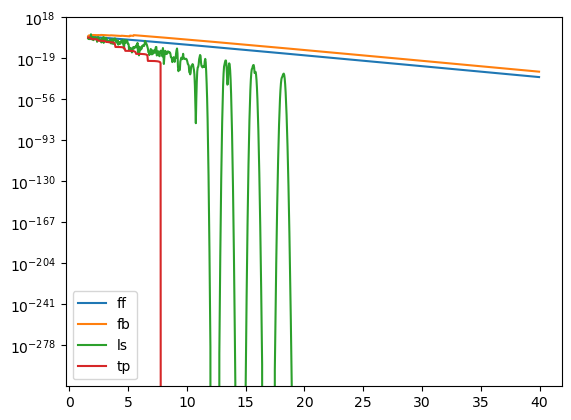

In [81]:
plt.plot(energies_of_interest, s.FreeFree['intensity'], label='ff')
plt.plot(energies_of_interest, s.FreeBound['intensity'], label='fb')
plt.plot(energies_of_interest, s.LineSpectrum['intensity'], label='ls')
plt.plot(energies_of_interest, s.TwoPhoton['intensity'], label='tp')
plt.yscale('log')
plt.legend()

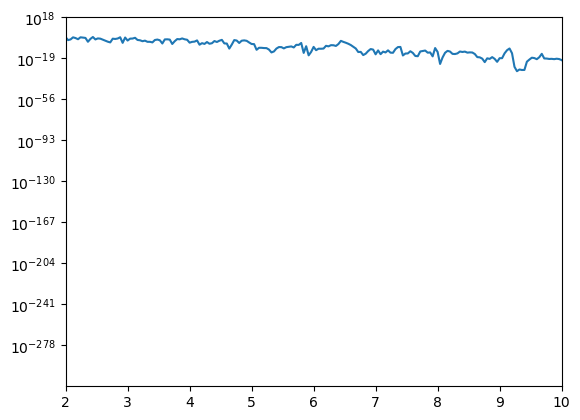

In [89]:
plt.plot(energies_of_interest, s.LineSpectrum['intensity'], label='ls')
plt.xlim([2,10])
plt.yscale('log')

In [48]:
dir(s)

['AbundAll',
 'Abundance',
 'AbundanceName',
 'Continuum',
 'Defaults',
 'EDensity',
 'Em',
 'Error',
 'Finished',
 'FreeBound',
 'FreeFree',
 'Intensity',
 'IonsCalculated',
 'Labels',
 'LineSpectrum',
 'MinAbund',
 'NTempDens',
 'Ndens',
 'Ntemp',
 'Spectrum',
 'Temperature',
 'Todo',
 'Total',
 'TwoPhoton',
 'Wavelength',
 'WvlRange',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'argCheck',
 'intensityList',
 'intensityPlot',
 'intensityRatio',
 'intensityRatioSave',
 'ionGate',
 'lineSpectrumPlot',
 'restoreData',
 'saveData',
 'spectrumPlot']

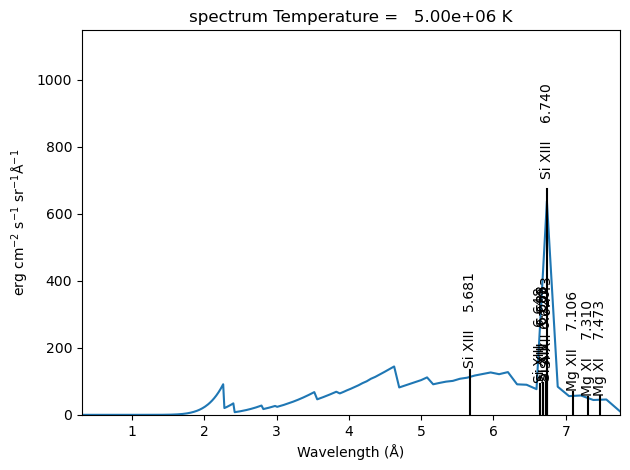

In [90]:
s.spectrumPlot()

In [91]:
s.IonsCalculated

['al_11',
 'al_12',
 'al_13',
 'ar_16',
 'ar_17',
 'ar_18',
 'ca_18',
 'ca_19',
 'ca_20',
 'cl_15',
 'cl_16',
 'cl_17',
 'co_22',
 'co_23',
 'co_24',
 'co_25',
 'cr_22',
 'cr_23',
 'fe_18',
 'fe_19',
 'fe_20',
 'fe_21',
 'fe_22',
 'fe_23',
 'fe_24',
 'fe_25',
 'k_17',
 'k_18',
 'k_19',
 'mg_10',
 'mg_11',
 'mg_12',
 'mn_23',
 'ne_9',
 'ni_23',
 'ni_24',
 'ni_25',
 'ni_26',
 'ni_27',
 'p_13',
 'p_14',
 'p_15',
 's_14',
 's_15',
 's_16',
 'si_12',
 'si_13',
 'si_14',
 'ti_21',
 'zn_21',
 'zn_25',
 'zn_28']